In [414]:
from pathlib import Path
import pandas as pd

CSV_PATH = Path("historique_merged.csv")

with CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

3 757 220 lignes dans le fichier


In [415]:
df = pd.read_csv(CSV_PATH, header=None)
print(df.shape)
df.head()

(3757220, 8)


,0,1,2,3,4,5,6,7
0,2026-10-16T11:52Z,10003,17,1,1,Hauteville - Bonne Nouvelle,"48.87077,2.34965",True
1,2026-10-16T11:52Z,10004,48,1,4,Metz - Faubourg Saint-Denis,"48.87089,2.35352",True
2,2026-10-16T11:52Z,10005,17,0,9,Petites Ecuries - Faubourg Poissonnière,"48.87397,2.34839",True
3,2026-10-16T11:52Z,10006,28,3,20,Petites Ecuries - Faubourg Saint-Denis,"48.87287,2.35422",True
4,2026-10-16T11:52Z,10008,18,4,2,Cité Riverin - Château d'Eau,"48.87070,2.35874",True


In [417]:
# Renommer les colonnes et convertir les types de données
COLONNES = [
    "horodatage", "station_code", "capacity", "velo_meca", "velo_elec",
    "station_name", "coordonnees", "operative",
]

df = pd.read_csv(CSV_PATH, header=None, names=COLONNES)
df["horodatage"] = pd.to_datetime(df["horodatage"], utc=True)
df[["latitude", "longitude"]] = df["coordonnees"].str.split(",", expand=True).astype(float)
df = df.drop(columns="coordonnees")

In [418]:
# Fusion des colonnes "velo_meca" et #velo_elec" pour créer une nouvelle colonne "available" 
df["available"] = df["velo_meca"] + df["velo_elec"]

In [419]:
# Ecarter les stations en dehors de Paris 
dans_paris = df["latitude"].between(48.815, 48.902) & df["longitude"].between(2.224, 2.470)
df = df[dans_paris].copy()

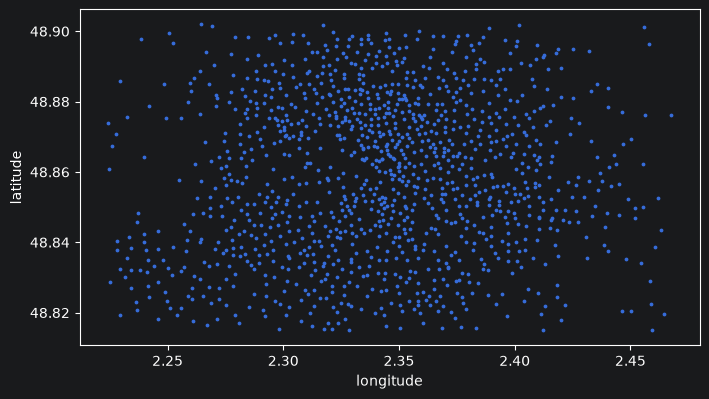

In [420]:
# Voir ce que ça donne sur une carte 
import numpy as np

stations = df.drop_duplicates("station_code")
ax = stations.plot.scatter(x="longitude", y="latitude", s=3, figsize=(8, 8))
ax.set_aspect(1 / np.cos(np.radians(48.86)))

In [421]:
# Suppressions des stations à capacité nulle (0)
df = df[df["capacity"] > 0].copy()

In [422]:
# Vérification 
print(df["capacity"].min()) 
print((df["capacity"] == 0).sum())

11
0


In [423]:
# Je vais chercher à isoler les cas problématiques, c-à-d les stations où la capacité est inférieur aux nombres de vélos dispo
anomalies = df[df["available"] > df["capacity"]].copy()
anomalies["exces"] = anomalies["available"] - anomalies["capacity"]

print(f"{len(anomalies):,} lignes sur {len(df):,} ({len(anomalies) / len(df):.2%})")
print(f"{anomalies['station_code'].nunique()} stations sur {df['station_code'].nunique()}")
anomalies["exces"].describe()

7,463 lignes sur 3,004,147 (0.25%)
17 stations sur 1215


count    7463.000000
mean        9.544687
std         8.191153
min         1.000000
25%         3.000000
50%         7.000000
75%        14.000000
max        40.000000
Name: exces, dtype: float64

In [424]:
# Trouver les cas les plus extrêmes 
anomalies.sort_values("exces", ascending=False).head(10)[
    ["horodatage", "station_code", "station_name", "capacity", "velo_meca", "velo_elec", "operative", "exces"]
]

,horodatage,station_code,station_name,capacity,velo_meca,velo_elec,operative,exces
3250133,2026-10-24 14:25:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3247095,2026-10-24 14:15:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3259247,2026-10-24 14:55:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3257728,2026-10-24 14:50:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3256209,2026-10-24 14:45:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3254690,2026-10-24 14:40:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3253171,2026-10-24 14:35:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3251652,2026-10-24 14:30:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,45,37,True,40
3248614,2026-10-24 14:20:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40
3245576,2026-10-24 14:10:00+00:00,13123,BNF - Bibliothèque Nationale de France,42,46,36,True,40


In [425]:
# 1. Lignes entièrement identiques (toutes les occurrences marquées)
full_dups = df[df.duplicated(keep=False)]

In [426]:
# 2. Doublons sur la clé logique : même station au même instant
key_dups = df[df.duplicated(subset=["horodatage", "station_code"], keep=False)]
key_dups = key_dups.sort_values(["station_code", "horodatage"])

In [427]:
print(f"Lignes identiques : {len(full_dups)}")
print(f"Doublons (timestamp, station_id) : {len(key_dups)}")
print(key_dups)

Lignes identiques : 0
Doublons (timestamp, station_id) : 0
Empty DataFrame
Columns: [horodatage, station_code, capacity, velo_meca, velo_elec, station_name, operative, latitude, longitude, available]
Index: []


In [428]:
# 3. Pour nettoyer en gardant la première occurrence mais pas besoin parce que pas de doublons
df = df.drop_duplicates(subset=["horodatage", "station_code"], keep="first")

Création d'une variable cible


In [429]:
# trie selon le code de station et l'heure pour compter la disponibilité dans 30 min
df = df.sort_values(["station_code", "horodatage"]).reset_index(drop=True)

In [430]:
# On cherche la ligne exactement 30 min plus tard
future = df[["station_code", "horodatage", "available"]].copy()
future["horodatage"] = future["horodatage"] - pd.Timedelta(minutes=30)
future = future.rename(columns={"available": "available_t30"})

In [431]:
df = df.merge(future, on=["station_code", "horodatage"], how="left")
# pour convertir en Int et pas float
df["available_t30"] = df["available_t30"].astype("Int64")

In [433]:
# Pour répérer les nan pour voir la proportion des données manquantes
n_na = df["available_t30"].isna().sum()
print(f"NA : {n_na} / {len(df)} ({n_na / len(df):.1%})")

NA : 133647 / 3004147 (4.4%)


In [434]:
# ecarter des valeurs manquantes après le shift
df = df.dropna(subset=["available_t30"]).reset_index(drop=True)

In [435]:
# introduire la tendance
df["delta_t30"] = df["available_t30"] - df["available"]

# Catégorie lisible le stock monte, baisse ou reste stable
df["tendance"] = pd.cut(
    df["delta_t30"],
    bins=[-float("inf"), -1, 0, float("inf")],
    labels=["baisse", "stable", "hausse"],
)

In [437]:
# introduire representation cyclique de heure
heure_dec = df["horodatage"].dt.hour + h.dt.minute / 60

df["heure_sin"] = np.sin(2 * np.pi * heure_dec / 24)
df["heure_cos"] = np.cos(2 * np.pi * heure_dec / 24)

In [438]:
# introduire is weekend
df["is_weekend"] = df["horodatage"].dt.dayofweek >= 5
df

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_t30,delta_t30,tendance,heure_sin,heure_cos,is_weekend
0,2026-10-16 13:20:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,14,7,hausse,-0.342020,-9.396926e-01,False
1,2026-10-16 13:25:00+00:00,1001,17,2,5,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,7,13,6,hausse,-0.362438,-9.320079e-01,False
2,2026-10-16 13:35:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse,-0.402747,-9.153115e-01,False
3,2026-10-16 13:40:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse,-0.422618,-9.063078e-01,False
4,2026-10-16 13:45:00+00:00,1001,17,7,7,Quai de l'Horloge - Pont Neuf,True,48.85706,2.34180,14,13,-1,baisse,-0.442289,-8.968727e-01,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2870495,2026-10-25 17:45:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,-0.997859,-6.540313e-02,True
2870496,2026-10-25 17:50:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,-0.999048,-4.361939e-02,True
2870497,2026-10-25 17:55:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,-0.999762,-2.181489e-02,True
2870498,2026-10-25 18:00:00+00:00,60002,409,0,0,Concorde - Place de la Madeleine,False,48.87062,2.32422,0,0,0,stable,-1.000000,-1.836970e-16,True


Dynamique Globale







In [439]:
print(df["delta_t30"].describe())
print(df["tendance"].value_counts(normalize=True))

count    2870500.0
mean      -0.00179
std       2.110412
min          -65.0
25%           -1.0
50%            0.0
75%            1.0
max           45.0
Name: delta_t30, dtype: Float64
tendance
stable    0.404482
baisse    0.299067
hausse    0.296450
Name: proportion, dtype: float64


In [440]:
# voir les lignes ou la delta min -65
df[df["delta_t30"] == df["delta_t30"].min()]

,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,available_t30,delta_t30,tendance,heure_sin,heure_cos,is_weekend
1028398,2026-10-23 19:50:00+00:00,12108,66,51,14,Bercy.,True,48.83997,2.37886,65,0,-65,baisse,-0.887011,0.461749,False
1028399,2026-10-23 19:55:00+00:00,12108,66,51,14,Bercy.,True,48.83997,2.37886,65,0,-65,baisse,-0.876727,0.480989,False
1028400,2026-10-23 20:00:00+00:00,12108,66,51,14,Bercy.,True,48.83997,2.37886,65,0,-65,baisse,-0.866025,0.500000,False


Dynamique par station

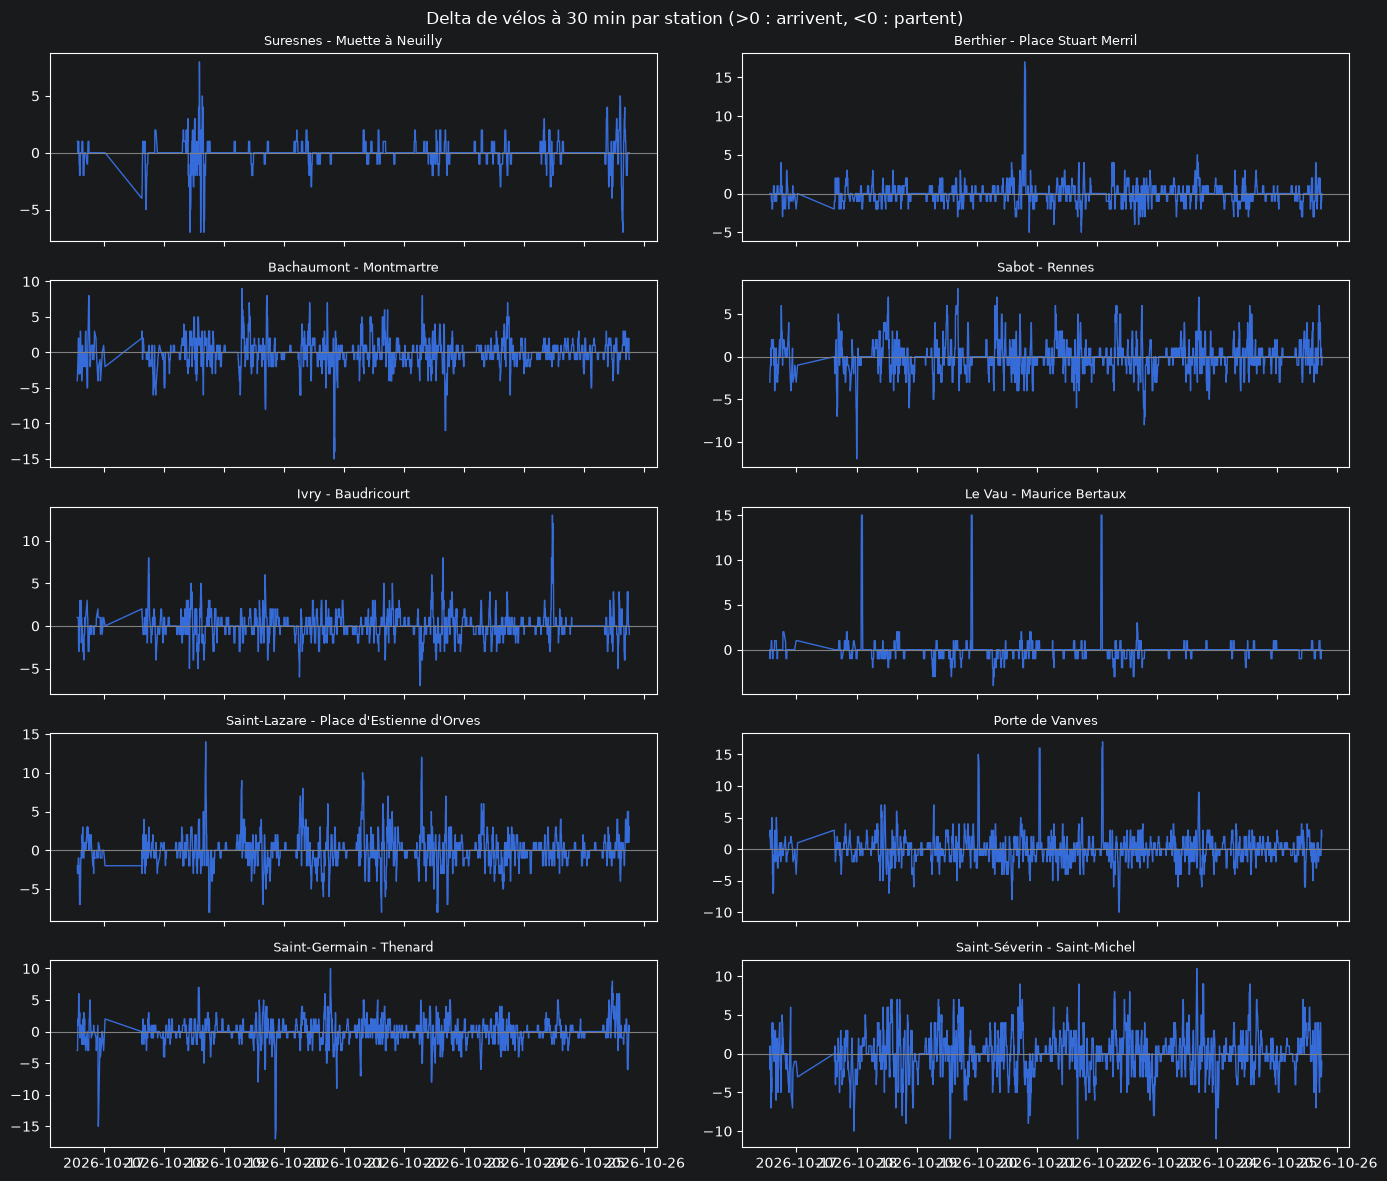

In [441]:
import matplotlib.pyplot as plt

# 10 stations au hasard (random_state fixe pour retrouver les mêmes)
codes = df["station_code"].drop_duplicates().sample(10, random_state=42)

fig, axes = plt.subplots(5, 2, figsize=(14, 12), sharex=True)

for ax, code in zip(axes.flat, codes):
    d = df[df["station_code"] == code].sort_values("horodatage")
    nom = d["station_name"].iloc[0]
    ax.plot(d["horodatage"], d["delta_t30"], linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_title(nom, fontsize=9)

fig.suptitle("Delta de vélos à 30 min par station (>0 : arrivent, <0 : partent)")
plt.tight_layout()
plt.show()

Dynamique par l'heure


<Axes: title={'center': 'Delta moyen à 30 min par heure (Paris)'}, xlabel='heure'>

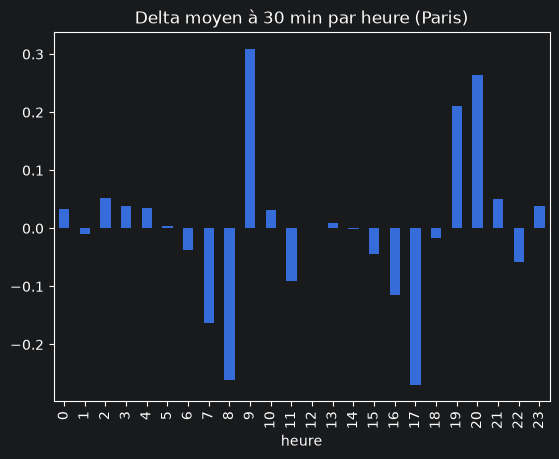

In [442]:
# introduction d'une colonne heure qui signifie l'heure de Paris pour les statistiques en bonne timezone
df["heure"] = df["horodatage"].dt.tz_convert("Europe/Paris").dt.hour
profil_horaire = df.groupby("heure")["delta_t30"].mean()
profil_horaire.plot(kind="bar", title="Delta moyen à 30 min par heure (Paris)")

Les rush hours


En semaine

Rush hours (semaine) : [8, 9, 17, 18, 19, 20]


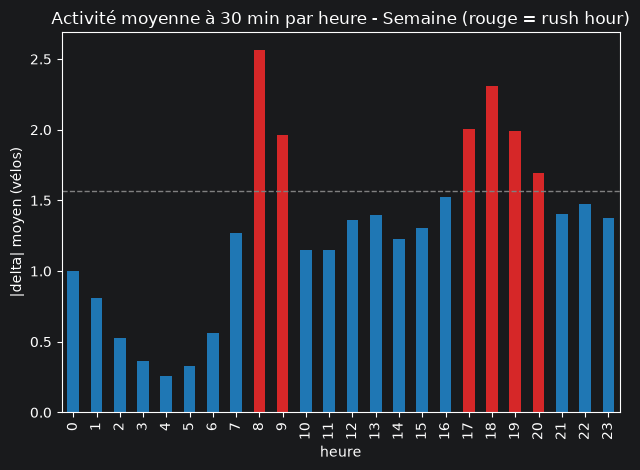

In [443]:
# valeur absolue de delta
df["delta_abs"] = df["delta_t30"].abs()
semaine = df[~df["is_weekend"]]

# Activité moyenne par heure
activite = semaine.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
print("Rush hours (semaine) :", rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Semaine (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()

En weekend

Rush hours (week-end) : [12, 14, 15, 17, 18, 19]


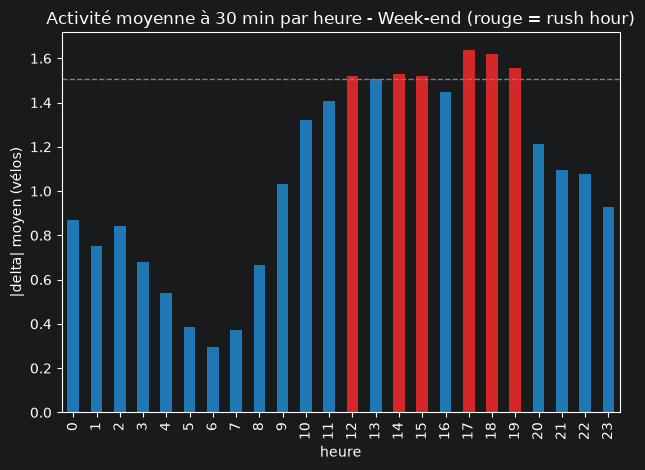

In [444]:
weekend = df[df["is_weekend"]]

# Activité moyenne par heure
activite = weekend.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
weekend_rush_hours = rush_hours
print("Rush hours (week-end) :", weekend_rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure - Week-end (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")
plt.tight_layout()
plt.show()

Rush hours : [8, 9, 17, 18, 19, 20]


Text(0, 0.5, '|delta| moyen (vélos)')

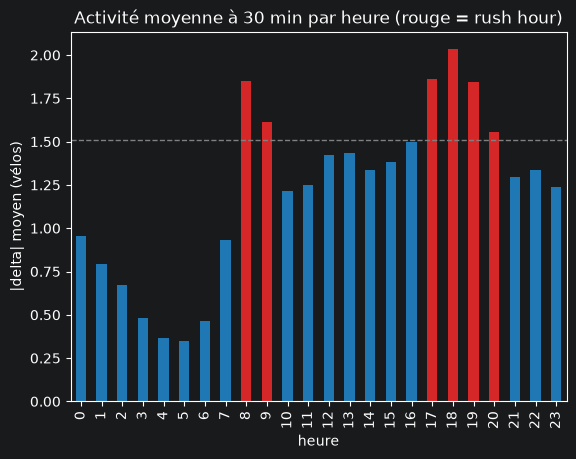

In [454]:
# Activité moyenne par heure
activite = df.groupby("heure")["delta_abs"].mean()

# Rush hour = heures dans les 25 % les plus actives
seuil = activite.quantile(0.75)
rush_hours = activite[activite >= seuil].index.tolist()
week_rush_hours = rush_hours
print("Rush hours :", week_rush_hours)

# Graphique : rush hours en rouge
couleurs = ["tab:red" if h in rush_hours else "tab:blue" for h in activite.index]
ax = activite.plot(kind="bar", color=couleurs,
                   title="Activité moyenne à 30 min par heure (rouge = rush hour)")
ax.axhline(seuil, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("|delta| moyen (vélos)")

In [456]:
# introduction de rush hour chaque ligne
df["is_rush_hour"] = (
    (df["is_weekend"] & df["heure"].isin(weekend_rush_hours))
    | (~df["is_weekend"] & df["heure"].isin(week_rush_hours))
)

Les données météo

In [446]:
METEO_CSV_PATH = Path("meteo_paris_octobre_2026.csv")

with METEO_CSV_PATH.open("rb") as f:
    nb_lignes = sum(1 for _ in f)
print(f"{nb_lignes:,} lignes dans le fichier".replace(",", " "))

961 lignes dans le fichier


In [447]:
meteo = pd.read_csv(METEO_CSV_PATH)
print(meteo.shape)
meteo.head()

(960, 8)


,date,temperature_2m,apparent_temperature,precipitation,weather_code,wind_speed_10m,rain,weather_label
0,2026-10-16 00:00:00+00:00,16.319500,16.440550,0.0,0.0,5.815978,0.0,Clear sky
1,2026-10-16 00:15:00+00:00,16.269500,16.389246,0.0,1.0,6.151683,0.0,Mainly clear
2,2026-10-16 00:30:00+00:00,16.219501,16.339570,0.0,1.0,6.034700,0.0,Mainly clear
3,2026-10-16 00:45:00+00:00,16.219501,16.339570,0.0,1.0,6.034700,0.0,Mainly clear
4,2026-10-16 01:00:00+00:00,16.169500,16.272877,0.0,1.0,6.034700,0.0,Mainly clear


In [448]:
meteo = meteo.rename(columns={"date": "horodatage"})
meteo["horodatage"] = pd.to_datetime(meteo["horodatage"], utc=True)
meteo.columns.tolist()

['horodatage',
 'temperature_2m',
 'apparent_temperature',
 'precipitation',
 'weather_code',
 'wind_speed_10m',
 'rain',
 'weather_label']

In [449]:
cols_continues = ["temperature_2m", "wind_speed_10m"]
cols_cumul = ["precipitation", "rain"]
cols_label = ["weather_label"]
cols_meteo = cols_continues + cols_cumul + cols_label

m = (meteo.drop_duplicates("horodatage")
       .sort_values("horodatage")
       .set_index("horodatage"))

# L'index porte le nom horodatage
heure_cibles = pd.DatetimeIndex(df["horodatage"].unique(), name="horodatage").sort_values()
index_union = m.index.union(heure_cibles)
base = pd.DataFrame({"horodatage": heure_cibles})

# on interpole des colonnes avec valeur lineeaires
interp = (m[cols_continues].reindex(index_union)
          .interpolate(method="time", limit_area="inside")
          .reindex(heure_cibles))

# pluie et precipitations ce sont des données accumulées delta de 15 min
cumul = pd.merge_asof(
    base, m[cols_cumul].reset_index(),
    on="horodatage", direction="backward", tolerance=pd.Timedelta(minutes=15),
).set_index("horodatage")

# etiquettes le plus proche de 8 mins
label = pd.merge_asof(
    base, m[cols_label].reset_index(),
    on="horodatage", direction="nearest", tolerance=pd.Timedelta(minutes=8),
).set_index("horodatage")

meteo_aligned = pd.concat([interp, cumul, label], axis=1)
meteo_aligned.index.name = "horodatage"          # sécurité
df = df.merge(meteo_aligned.reset_index(), on="horodatage", how="left")

In [450]:
print(df[cols_meteo].isna().mean()) # si 0 partout c'est bien
echantillon = df.sample(100, random_state=42).sort_values("horodatage")
echantillon

temperature_2m    0.0
wind_speed_10m    0.0
precipitation     0.0
rain              0.0
weather_label     0.0
dtype: float64


,horodatage,station_code,capacity,velo_meca,velo_elec,station_name,operative,latitude,longitude,available,...,heure_cos,is_weekend,heure,delta_abs,is_rush_hour,temperature_2m,wind_speed_10m,precipitation,rain,weather_label
830460,2026-10-17 15:45:00+00:00,11016,48,0,2,Philippe-Auguste,True,48.85185,2.39329,2,...,-0.555570,True,17,1,True,15.219500,15.141414,0.0,0.0,Overcast
2816269,2026-10-17 20:21:00+00:00,42026,40,4,4,Barbès - Monique Maunoury,True,48.81553,2.36872,8,...,0.577145,True,22,1,False,10.909500,12.240000,0.0,0.0,Mainly clear
2178005,2026-10-17 23:45:00+00:00,19128,30,3,1,Quai de l'Oise - Aisne,True,48.89062,2.38337,4,...,0.997859,True,1,1,False,9.119500,10.799999,0.0,0.0,Mainly clear
287797,2026-10-18 00:35:00+00:00,5122,29,2,2,Saint-Michel - Luxembourg,True,48.84502,2.33949,4,...,0.988362,True,2,2,False,8.786167,9.966506,0.0,0.0,Partly cloudy
1570482,2026-10-18 01:50:00+00:00,15113,25,1,6,Arsonval - Falguière,True,48.84040,2.31312,7,...,0.887011,True,3,0,False,8.219500,8.825508,0.0,0.0,Mainly clear
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2045380,2026-10-25 11:10:00+00:00,18207,40,1,2,Coysevox - Lamarck,True,48.89107,2.32934,3,...,-0.976296,True,12,1,True,14.869499,25.922499,0.0,0.0,Partly cloudy
1808989,2026-10-25 11:55:00+00:00,17027,46,13,0,Place du Maréchal Juin - Péreire,True,48.88526,2.29829,13,...,-0.999762,True,12,3,True,15.236166,24.031554,0.0,0.0,Partly cloudy
2234514,2026-10-25 12:20:00+00:00,20016,33,0,0,Pyrénées - Maraîchers,True,48.85714,2.40435,0,...,-0.996195,True,13,4,False,15.269500,23.323589,0.0,0.0,Partly cloudy
1804302,2026-10-25 15:20:00+00:00,17025,35,3,1,Chazelles - Courcelles,True,48.87941,2.30345,4,...,-0.642788,True,16,0,False,15.086166,24.222812,0.0,0.0,Partly cloudy


In [452]:
# derniere normalisation des valeurs de meteo
cols_num = ["temperature_2m", "wind_speed_10m", "precipitation", "rain"]
df[cols_num] = df[cols_num].apply(pd.to_numeric, errors="coerce").astype("float64").round(2)

## Export du dataset nettoyé

In [ ]:
SORTIE = Path("raw/data/historique_nettoye.csv")
SORTIE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(SORTIE, index=False)